# Question 1 :
An airline tracks flight delays (in minutes) for 20 flights. Analyze the flight delays to calculate percentiles, detect outliers, and evaluate the overall distribution.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio

In [2]:
delays = [15, 30, 45, 20, 25, 100, 5, 60, 35, 50, 
          120, 80, 10, 75, 90, 200, 55, 40, 70, 150]
df = pd.DataFrame(delays)


In [3]:
# Percentile calculation
percentile = np.percentile(delays,[10,25,50,75,90])
print(f"Percentiles (10th, 25th, 50th, 75th, 90th): {percentile}")

# IQR calculation
q1,q3 = percentile[1],percentile[3]
Iqr = q3-q1
print(f"IQR: {Iqr}")

# Outilers
lower_bound = q1 - (1.5*Iqr)
upper_bound = q3 + (1.5*Iqr)
outliers = [i for i in delays if i<lower_bound or i>upper_bound]
print(f"Outliers: {outliers}")

Percentiles (10th, 25th, 50th, 75th, 90th): [ 14.5   28.75  52.5   82.5  123.  ]
IQR: 53.75
Outliers: [200]


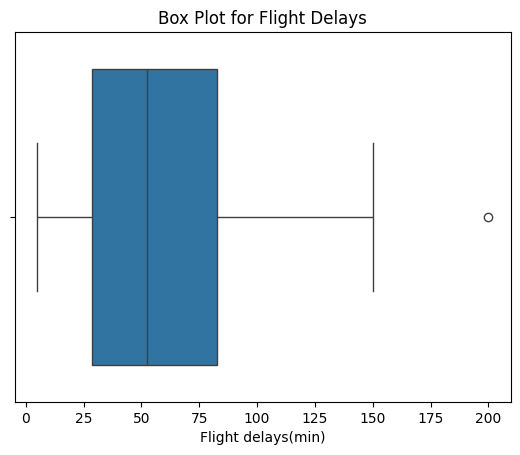

In [4]:
sns.boxplot(x=delays)
plt.xlabel("Flight delays(min)")
plt.title("Box Plot for Flight Delays")
plt.show()

# Question 2 :
A company wants to analyze the salary distribution of its employees to understand the central tendency and determine whether the data is skewed.


In [5]:
salaries = [30000, 32000, 35000, 37000, 40000, 42000, 45000, 47000, 50000, 55000,
            60000, 62000, 65000, 67000, 70000, 72000, 75000, 80000, 85000, 90000]


In [6]:
from scipy import stats

In [7]:
mean_val= np.mean(salaries)
median_val=np.median(salaries)
mode_val=stats.mode(salaries,keepdims=True).mode[0]

print("Mean Salary:",mean_val)
print("Median Salary:",median_val)
print("Mode Salary:",mode_val)

Mean Salary: 56950.0
Median Salary: 57500.0
Mode Salary: 30000


The data is Left Skewed (Negative Skew)


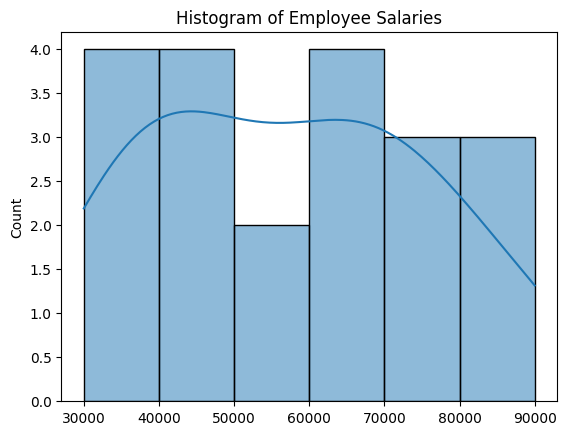

In [8]:
if (mean_val > median_val):
    print("The data is Right Skewed (Positive Skew)")
elif (mean_val < median_val):
    print("The data is Left Skewed (Negative Skew)")
else:
    print("The data is Symmetrical")

sns.histplot(x=salaries,kde=True)
plt.title("Histogram of Employee Salaries")
plt.show()

# Question 3:
 A school wants to analyze the exam performance of students across three subjects: Mathematics, Science, and English. How can Data Science concepts be applied to understand their performance?


In [9]:
data = {
    'Student': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'],
    'Mathematics': [85, 78, 92, 88, 70, 95, 60, 80, 90, 76],
    'Science': [80, 85, 88, 70, 75, 92, 55, 82, 89, 78],
    'English': [78, 74, 85, 80, 68, 90, 50, 77, 83, 72]
}
df = pd.DataFrame(data)
df

,Student,Mathematics,Science,English
0,A,85,80,78
1,B,78,85,74
2,C,92,88,85
3,D,88,70,80
4,E,70,75,68
5,F,95,92,90
6,G,60,55,50
7,H,80,82,77
8,I,90,89,83
9,J,76,78,72


In [10]:
df.isnull().sum()

Student        0
Mathematics    0
Science        0
English        0
dtype: int64

In [11]:
# Descriptive stats
print(f"Discriptive Statistics:\n {df.describe()}")

Discriptive Statistics:
        Mathematics    Science    English
count    10.000000  10.000000  10.000000
mean     81.400000  79.400000  75.700000
std      10.844353  10.895463  11.086027
min      60.000000  55.000000  50.000000
25%      76.500000  75.750000  72.500000
50%      82.500000  81.000000  77.500000
75%      89.500000  87.250000  82.250000
max      95.000000  92.000000  90.000000


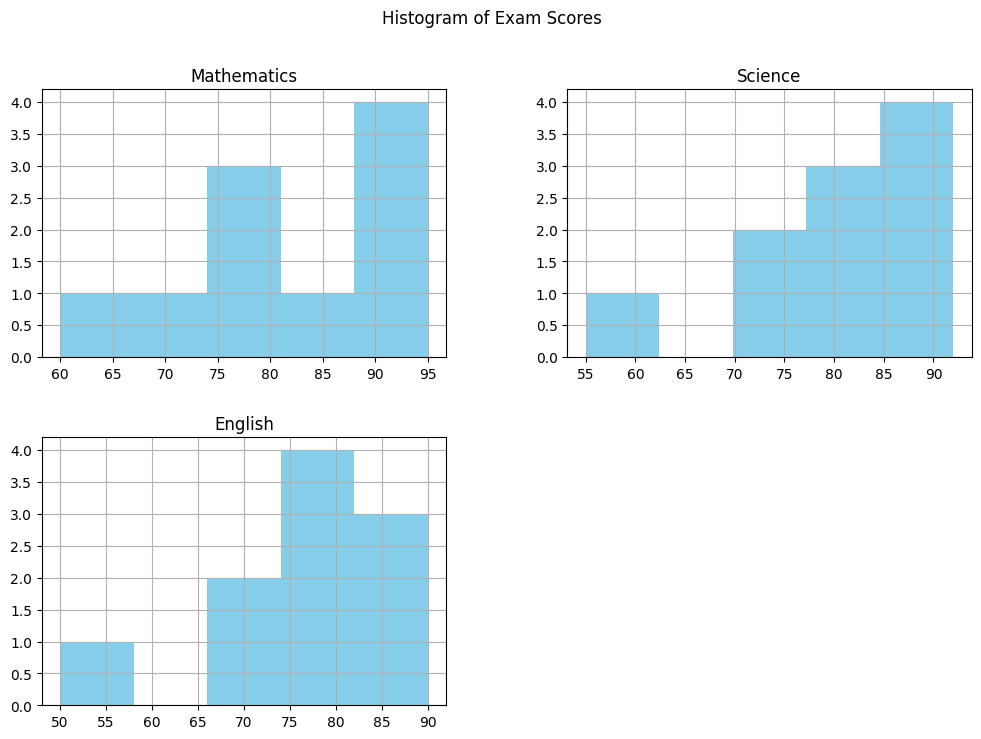

In [12]:
# Histogram
df[['Mathematics', 'Science', 'English']].hist(bins=5, figsize=(12,8), color='skyblue')
plt.suptitle('Histogram of Exam Scores')
plt.show()

In [13]:
print(f"Correlation Matrix:\n {df[['Mathematics', 'Science', 'English']].corr()}")

Correlation Matrix:
              Mathematics   Science   English
Mathematics     1.000000  0.792185  0.974318
Science         0.792185  1.000000  0.874999
English         0.974318  0.874999  1.000000


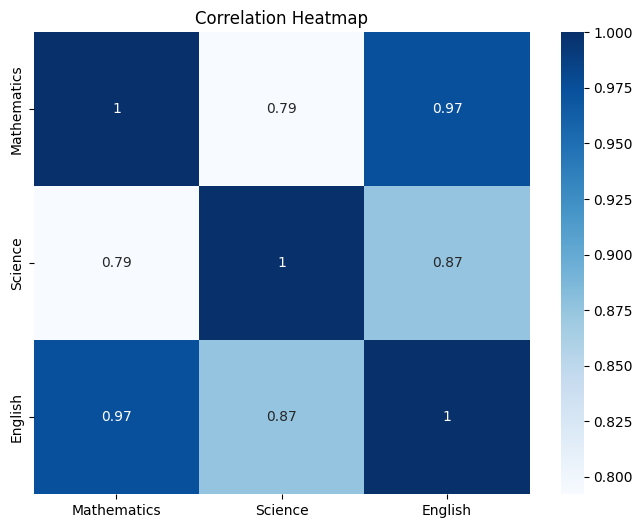

In [14]:
# Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[['Mathematics', 'Science', 'English']].corr(), annot=True, cmap='Blues')
plt.title('Correlation Heatmap')
plt.show()

# Question 4:
A pharmaceutical company conducted a clinical trial with two groups: one receiving medication and the other a placebo. How do you perform a hypothesis test to determine the effectiveness of the medication?


In [15]:
medication_group = [110, 115, 108, 102, 107, 99, 111, 104, 109, 101]
placebo_group = [120, 125, 130, 122, 128, 119, 124, 127, 123, 126]


# Hypothesis

H0: The medication is not effective

H1: The medication is effective

In [16]:
# Perform an independent T-test 
t_stat, p_value = stats.ttest_ind(medication_group, placebo_group)

# Output results
print(f"T-Statistic: {t_stat}")
print(f"P-Value: {p_value}")

T-Statistic: -9.201427649220966
P-Value: 3.163912817600812e-08


In [17]:
if p_value <= 0.05:
    print("Reject the null hypothesis: The medication is effective.")
else:
    print("Fail to reject the null hypothesis: No significant effect of the medication.")

Reject the null hypothesis: The medication is effective.


# Question 5:
 A company conducted a customer satisfaction survey where customers rated their experience on a scale of 1 to 10. Analyze the survey results to calculate descriptive statistics and visualize the distribution of customer satisfaction ratings.

In [18]:
ratings = [8, 9, 7, 5, 6, 10, 9, 4, 7, 8, 
           6, 9, 10, 5, 8, 7, 6, 9, 10, 7]


In [19]:
# Calculate descriptive statistics
mean_rating = np.mean(ratings)
median_rating = np.median(ratings)
mode_rating = stats.mode(ratings, keepdims=True).mode[0]
std_dev = np.std(ratings)

print(f"Mean Rating: {mean_rating}")
print(f"Median Rating: {median_rating}")
print(f"Mode Rating: {mode_rating}")
print(f"Standard Deviation: {std_dev}")

Mean Rating: 7.5
Median Rating: 7.5
Mode Rating: 7
Standard Deviation: 1.746424919657298


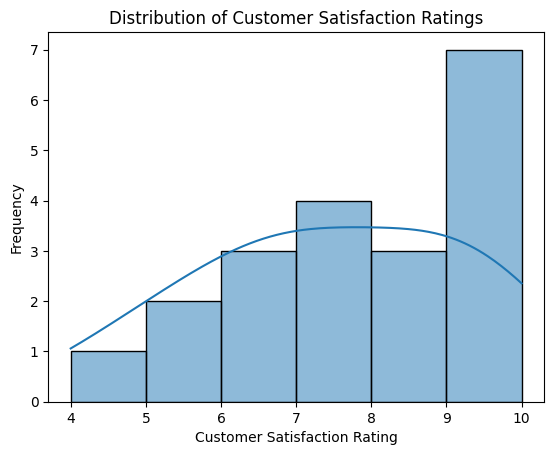

In [20]:
# Histogram
sns.histplot(ratings, kde=True)
plt.xlabel('Customer Satisfaction Rating')
plt.ylabel('Frequency')
plt.title('Distribution of Customer Satisfaction Ratings')
plt.show()